# Quantum Execution Integrity Challenge: Group 07 solution

This notebook presents our solution to both scored stages and summarises the optional bonus. It is a
walkthrough of the submitted code, not a replacement for it:

* **`solve.py`** contains the forensic analysis (`solve_stage1`, `solve_stage2`).
* **`outputs/result.json`** was generated from that exact `solve.py` by `evaluate.py`.
* **`extensions/`** holds the bonus work (B1 Quantum Metal, B2 scqubits, B3 QuTiP).

Every number shown here is computed live from the frozen artifacts in `stages/*/artifacts/`. Nothing is
hard-coded. The notebook does not modify any artifact or `result.json`.

| Stage | Verdict | Root cause |
|---|---|---|
| 1 | `INTEGRITY_VIOLATION` | Stale control binding `bind_73` (K19 profile `cp_017`/`u12`, physical 1→2) drives `cx_1_2` after maintenance moved q2 to physical 4 |
| 2 | `INTEGRITY_VIOLATION` | Device model `model-20` derived from D20 geometry (g = 16 MHz) on a D21 device (g = 18 MHz); calibration inherits it, so RZZ(π/2) is realized as RZZ(9π/16) |

**How to run:** from the repository root, with `requirements-core.txt` installed (plus `matplotlib`), open
this notebook and run all cells. It works whether the kernel starts in the repo root or in `outputs/`.

In [1]:
import json, math, sys, importlib.util, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'solve.py').exists() and (p / 'stages').exists())
S1, S2 = ROOT / 'stages/stage_1/artifacts', ROOT / 'stages/stage_2/artifacts'
spec = importlib.util.spec_from_file_location('solve', ROOT / 'solve.py')
solve = importlib.util.module_from_spec(spec); spec.loader.exec_module(solve)
J = lambda d, n: json.loads((d / n).read_text())
import qiskit, qiskit_aer
print('repo root:', ROOT)
print('python', sys.version.split()[0], '| qiskit', qiskit.__version__, '| qiskit-aer', qiskit_aer.__version__, '| numpy', np.__version__)

repo root: /home/user/csaw-qeic-group-07
python 3.13.18 | qiskit 2.6.2 | qiskit-aer 0.18.2 | numpy 2.5.4


In [2]:
# The submitted result must correspond to the submitted solve.py (hash check) and be structurally valid.
r = subprocess.run([sys.executable, 'validate_submission.py', 'outputs/result.json', '--submission', 'solve.py'],
                   cwd=ROOT, capture_output=True, text=True)
print(r.stdout or r.stderr)

submission structurally valid; final correctness scoring is organizer-side



## Stage 1: execution-stack forensics

**Question.** Did the 3-qubit GHZ job (`job_20_8841`) run what was requested?

We trace each layer in turn: intended → compiled → mapping → schedule → control binding → calibration → counts.

In [3]:
from qiskit import qpy
def instrs(c):
    return [(i.operation.name, [c.find_bit(q).index for q in i.qubits], [round(float(p), 6) for p in i.operation.params],
             [c.find_bit(b).index for b in i.clbits]) for i in c.data]
circ = {n: qpy.load(open(S1 / f'{n}_circuit.qpy', 'rb'))[0] for n in ('intended', 'compiled')}
mapping = J(S1, 'mapping_current.json')['logical_to_physical']
print('current mapping', J(S1, 'mapping_current.json')['mapping_id'], mapping)
for k, (a, b) in enumerate(zip(*(instrs(circ[n]) for n in ('intended', 'compiled')))):
    print(f'{k}: intended {a[0]:7s} q{a[1]} {a[2]}  ->  compiled {b[0]:7s} phys{b[1]} {b[2]}')

current mapping M2 {'q0': 0, 'q1': 1, 'q2': 4}
0: intended rz      q[0] [1.570796]  ->  compiled rz      phys[0] [1.570796]
1: intended sx      q[0] []  ->  compiled sx      phys[0] []
2: intended rz      q[0] [1.570796]  ->  compiled rz      phys[0] [1.570796]
3: intended cx      q[0, 1] []  ->  compiled cx      phys[0, 1] []
4: intended cx      q[1, 2] []  ->  compiled cx      phys[1, 4] []
5: intended measure q[0] []  ->  compiled measure phys[0] []
6: intended measure q[1] []  ->  compiled measure phys[1] []
7: intended measure q[2] []  ->  compiled measure phys[4] []


The compiled circuit matches the intended GHZ circuit instruction for instruction under mapping **M2**
(q0→0, q1→1, q2→4), so the compiler is consistent. Next we follow each two-qubit gate through the schedule,
its control binding and the calibration profile, to the physical qubits that profile actually drives.

In [4]:
backend = J(S1, 'backend.json'); n2p = {k: v['physical_index'] for k, v in backend['endpoint_registry'].items()}
sched = {o['id']: o for o in J(S1, 'schedule.json')['operations']}
manifest = J(S1, 'control_manifest.json')
cals = {c['calibration_epoch']: c for c in (J(S1, 'calibration_current.json'), J(S1, 'calibration_previous.json'))}
profiles = {p['profile_id']: dict(p, epoch=e) for e, c in cals.items() for p in c['profiles']}
print('current calibration epoch:', J(S1, 'calibration_current.json')['calibration_epoch'],
      '| job declares:', J(S1, 'execution_log.json')['calibration_epoch'])
for b in manifest['bindings']:
    op = next(o for o in sched.values() if o.get('control_binding') == b['binding_id'])
    prof = profiles[b['calibration_profile_id']]
    drives = [n2p[r] for r in prof['endpoint_refs']]
    ok = drives == op['physical_qubits'] and prof['epoch'] == 'K20'
    print(f"{op['id']} ({op['logical_operation']}) scheduled on {op['physical_qubits']} -> {b['binding_id']} "
          f"-> {prof['epoch']} profile {prof['profile_id']} on {prof['channel']} drives {drives}  {'OK' if ok else '<-- MISMATCH'}")
print('Unbound current-epoch profiles:', [p['profile_id'] + ' ' + str([n2p[r] for r in p['endpoint_refs']]) + ' on ' + p['channel']
       for p in J(S1, 'calibration_current.json')['profiles'] if p['profile_id'] not in {b['calibration_profile_id'] for b in manifest['bindings']}])

current calibration epoch: K20 | job declares: K20
ent_41 (cx_0_1) scheduled on [0, 1] -> bind_41 -> K20 profile cp_021 on u7 drives [0, 1]  OK
ent_73 (cx_1_2) scheduled on [1, 4] -> bind_73 -> K19 profile cp_017 on u12 drives [1, 2]  <-- MISMATCH
Unbound current-epoch profiles: ['cp_026 [1, 4] on u15']


**This is the fault.** `bind_73` still references the **K19** profile `cp_017` on channel `u12`, which drives
physical **(1, 2)**. It was created on 2026-05-02, before maintenance ticket `maint_2048` moved q2 from physical
2 to physical 4. The correct K20 profile for (1, 4), `cp_026` on `u15`, exists but is never bound.

Compiler, mapping and schedule were all updated; only the control binding was left stale. Next we check
whether the observed counts agree.

faithful CX(1->4)    TVD to observed = 0.503
misrouted CX(1->2)   TVD to observed = 0.037
CX omitted           TVD to observed = 0.037


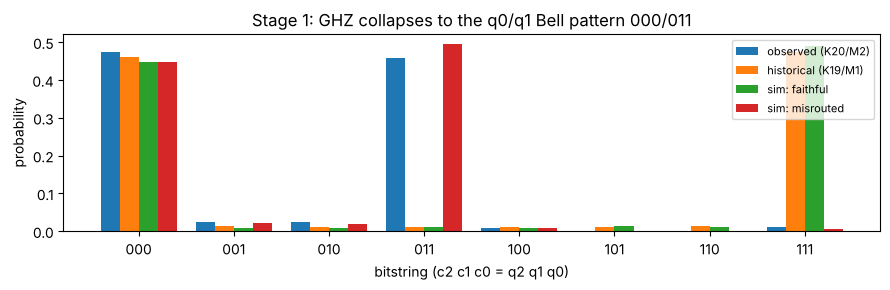

In [5]:
obs = J(S1, 'execution_counts.json')['counts']; hist = J(S1, 'historical_counts.json')['counts']
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError
nm = NoiseModel(); nm.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))
sim = AerSimulator(noise_model=nm, seed_simulator=20261113)
def ghz(target):              # probe qubit 3 = physical 4 (logical q2); probe qubit 2 = physical 2
    c = QuantumCircuit(4, 3); c.rz(math.pi/2, 0); c.sx(0); c.rz(math.pi/2, 0); c.cx(0, 1)
    if target is not None: c.cx(1, target)
    c.measure([0, 1, 3], [0, 1, 2]); return c
models = {'faithful CX(1->4)': ghz(3), 'misrouted CX(1->2)': ghz(2), 'CX omitted': ghz(None)}
tvd = lambda a, b: 0.5 * sum(abs(a.get(k, 0)/sum(a.values()) - b.get(k, 0)/sum(b.values())) for k in set(a) | set(b))
sims = {k: sim.run(c, shots=1536).result().get_counts() for k, c in models.items()}
for k, v in sims.items(): print(f'{k:20s} TVD to observed = {tvd(v, obs):.3f}')
keys = [format(i, '03b') for i in range(8)]
fig, ax = plt.subplots(figsize=(9, 3)); w = 0.2
for i, (lab, d) in enumerate([('observed (K20/M2)', obs), ('historical (K19/M1)', hist),
                              ('sim: faithful', sims['faithful CX(1->4)']), ('sim: misrouted', sims['misrouted CX(1->2)'])]):
    tot = sum(d.values()); ax.bar(np.arange(8) + (i - 1.5) * w, [d.get(k, 0)/tot for k in keys], w, label=lab)
ax.set_xticks(range(8)); ax.set_xticklabels(keys); ax.set_xlabel('bitstring (c2 c1 c0 = q2 q1 q0)'); ax.set_ylabel('probability')
ax.legend(fontsize=8); ax.set_title('Stage 1: GHZ collapses to the q0/q1 Bell pattern 000/011'); plt.tight_layout(); plt.show()

The observed counts are **000/011** (93%): q0 and q1 are entangled, but q2 (physical 4) never flips. The
historical K19/M1 run gave a clean GHZ (000/111). Under M1 the stale binding was still correct, because q2 sat
on physical 2.

The "misrouted" and "CX omitted" simulations fit the counts equally well, because physical 2 is never measured.
The realized edge (1,2) is therefore **inferred from the binding's provenance**, not from the counts. Our answer
states this, with lower confidence on that part, and proposes an edge-isolation probe to tell the two apart.

Incidental anomalies we reject:
- node_d (physical 3) has gate quality 0.86 and node_f (physical 5) has readout error 0.08, but neither qubit is used.
- `bind_41` moved channel from `u3` to `u7`; this is a legitimate recalibration of the correct edge.
- The CX durations differ.
- About 7% of counts fall outside the two dominant outcomes, consistent with 2% readout error per qubit plus gate noise.

The submitted Stage-1 answer:

In [6]:
s1 = solve.solve_stage1(S1)
print('verdict:', s1['verdict'], '| confidence:', s1['confidence'], '| fault type:', s1['suspected_fault_type'])
for k in ('affected_logical_operations', 'expected_physical_resources', 'suspected_realized_resources'):
    print(f'\n{k}:'); [print('  -', x) for x in s1[k]]
print('\nlayer assessments:'); [print(f'  [{k}] {v[:160]}...') for k, v in s1['layer_assessments'].items()]
print('\nproposed repair:', s1['proposed_repair'][:400], '...')

verdict: INTEGRITY_VIOLATION | confidence: 0.95 | fault type: STALE_CONTROL_BINDING_WRONG_PHYSICAL_EDGE (calibration provenance / epoch mismatch)

affected_logical_operations:
  - cx_1_2 (CX q1->q2; schedule op ent_73; binding bind_73)

expected_physical_resources:
  - physical qubits (1,4): CX control 1 -> target 4 (node_b->node_e)
  - K20 profile cp_026 on control channel u15

suspected_realized_resources:
  - physical qubits (1,2): CX control 1 -> target 2 (node_b->node_c)
  - stale K19 profile cp_017 on control channel u12 (bundle cb_73c, device epoch D19)

layer assessments:
  [compiler] CONSISTENT. All 8 compiled instructions equal the intended ones with qubits relabelled by mapping M2 (q0->0, q1->1, q2->4); gate names, RZ parameters and clbit ...
  [mapping] CONSISTENT. M2 agrees with mapping_history, the compiled circuit layout, the schedule and the execution log; device epoch D20 matches the backend. It replaced M...
  [scheduling] CONSISTENT. sched_6f31 references M2; every s

## Stage 2: cross-layer forensics (32 qubits)

**Question.** Did the 32-qubit workload's target interaction `op_00694`, an RZZ(π/2) on physical edge (1, 4),
execute as intended?

Compiler, mapping, schedule and runtime are all consistent; the solver checks each one. The fault is in the
**provenance chain** that runs from device design to device model to control calibration.

In [7]:
reg = J(S2, 'provenance_registry.json'); fp2rev = {r['geometry_fingerprint']: r['revision'] for r in reg['revisions']}
des, mod, cal, rt = J(S2, 'device_design.json'), J(S2, 'device_model.json'), J(S2, 'control_calibration.json'), J(S2, 'simulated_runtime_snapshot.json')
print(f"runtime         : revision {rt['device_revision']}  fingerprint -> {fp2rev[rt['geometry_fingerprint']]}  epoch {rt['calibration_epoch']}")
print(f"device design   : {des['artifact_id']}  fingerprint -> {fp2rev[des['geometry_fingerprint']]}  coupling g = {des['local_region']['coupling_proxy_MHz']} MHz")
print(f"device model    : {mod['artifact_id']}   source fingerprint -> {fp2rev[mod['source_geometry_fingerprint']]}  (created {mod['created_at']})  g = {mod['coupling_proxy_MHz']} MHz")
print(f"calibration     : {cal['artifact_id']}  model_ref = {cal['model_ref']}  nominal rate {cal['nominal_rate_rad_per_ns']:.6f} rad/ns "
      f"= 2*pi*{mod['coupling_proxy_MHz']}/1000 -> pulse {cal['pulse_duration_ns']} ns for pi/2")
rate = lambda g: 2 * math.pi * g / 1000
theta = rate(des['local_region']['coupling_proxy_MHz']) * cal['pulse_duration_ns']
print(f"\nrealized angle at the D21 coupling: {theta:.6f} rad = {theta/math.pi*16:.0f}*pi/16 (intended pi/2), over-rotation {math.degrees(theta - math.pi/2):.2f} deg")

runtime         : revision D21  fingerprint -> D21  epoch K21
device design   : design-21  fingerprint -> D21  coupling g = 18.0 MHz
device model    : model-20   source fingerprint -> D20  (created 2026-07-01T09:00:00Z)  g = 16.0 MHz
calibration     : cal-21  model_ref = model-20  nominal rate 0.100531 rad/ns = 2*pi*16.0/1000 -> pulse 15.625 ns for pi/2

realized angle at the D21 coupling: 1.767146 rad = 9*pi/16 (intended pi/2), over-rotation 11.25 deg


The device model was built from the **D20** geometry (g = 16 MHz) and never regenerated for **D21** (g = 18 MHz).
The K21 calibration took its rate from that model, so its 15.625 ns pulse rotates by **9π/16** instead of π/2.

Two independent records confirm this: the characterization probes and the full-device verification correlator.

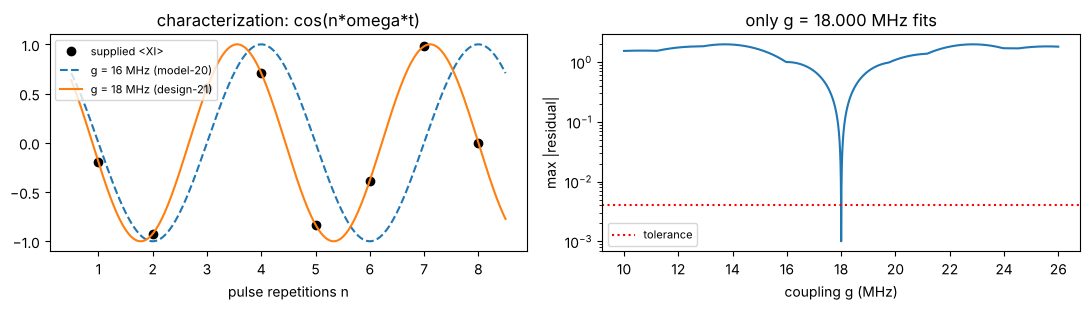

max residual: g=16 -> 1.001 | g=18 -> 0.001
verification <X1>: observed -0.193199 | predicted intended 0.000000 | predicted realized -0.193199


In [8]:
char = J(S2, 'characterization.json'); n = np.array([p['repetitions'] for p in char['probes']]); y = np.array([p['expectation'] for p in char['probes']])
t = cal['pulse_duration_ns']; nn = np.linspace(0.5, 8.5, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(n, y, 'ko', label='supplied <XI>'); ax[0].plot(nn, np.cos(nn * rate(16) * t), '--', label='g = 16 MHz (model-20)')
ax[0].plot(nn, np.cos(nn * rate(18) * t), '-', label='g = 18 MHz (design-21)'); ax[0].set_xlabel('pulse repetitions n'); ax[0].legend(fontsize=8)
ax[0].set_title('characterization: cos(n*omega*t)')
g = np.arange(10, 26, 0.001); res = np.max(np.abs(np.cos(np.outer(g, n) * rate(1) * t) - y), axis=1)
ax[1].semilogy(g, res); ax[1].axhline(char['absolute_tolerance'], color='r', ls=':', label='tolerance')
ax[1].set_xlabel('coupling g (MHz)'); ax[1].set_ylabel('max |residual|'); ax[1].legend(fontsize=8); ax[1].set_title('only g = 18.000 MHz fits')
plt.tight_layout(); plt.show()
print('max residual: g=16 ->', round(float(np.max(np.abs(np.cos(n*rate(16)*t) - y))), 4), '| g=18 ->', round(float(np.max(np.abs(np.cos(n*rate(18)*t) - y))), 4))

ver, obs2 = J(S2, 'verification_protocol.json'), J(S2, 'observable_spec.json')
vo = next(o for o in obs2['observables'] if o.get('circuit')); q = vo['qubits'][0]
pref = math.cos(ver['phase_angles_rad'][q]) * math.prod(math.cos(e['angle_rad']) for e in ver['interactions'] if q in e['edge'] and e['edge'] != [1, 4])
print(f"verification <X{q}>: observed {vo['observed_value']:.6f} | predicted intended {pref*math.cos(math.pi/2):.6f} | predicted realized {pref*math.cos(theta):.6f}")

**Structured simulation of the 32-qubit workload.** We use Aer `matrix_product_state` and request selected
observables only. Total Z-parity, the workload's built-in check, is 1.0 whether the target angle is right or
wrong, so it cannot detect the fault. Local observables on (1, 4) do shift.

In [9]:
from qiskit.quantum_info import Pauli
from qiskit_aer import AerSimulator
C2 = qpy.load(open(S2 / 'compiled_circuit.qpy', 'rb'))[0]; idx = J(S2, 'challenge.json')['circuit']['target_instruction_index']
def P(d): s = ['I']*32; [s.__setitem__(31-k, v) for k, v in d.items()]; return ''.join(s)
paulis = {'total parity': 'Z'*32, '<Z1>': P({1:'Z'}), '<Z4>': P({4:'Z'}), '<Z1 Z4>': P({1:'Z', 4:'Z'})}
def run(angle, bond):
    q = QuantumCircuit(32)
    for k, ins in enumerate(C2.data):
        q.append(ins.operation.__class__(angle) if k == idx else ins.operation, ins.qubits)
    for lab, p in paulis.items(): q.save_expectation_value(Pauli(p), range(32), label=lab)
    d = AerSimulator(method='matrix_product_state', matrix_product_state_max_bond_dimension=bond).run(q, shots=1).result().data(0)
    return {k: round(float(np.real(d[k])), 6) for k in paulis}
for bond in (128, 256):
    print(f'bond {bond}: intended', run(math.pi/2, bond), '\n          realized', run(theta, bond))

bond 128: intended {'total parity': 1.0, '<Z1>': 0.206961, '<Z4>': 0.381432, '<Z1 Z4>': 0.718743} 
          realized {'total parity': 1.0, '<Z1>': 0.078474, '<Z4>': 0.258211, '<Z1 Z4>': 0.675939}


bond 256: intended {'total parity': 1.0, '<Z1>': 0.206961, '<Z4>': 0.381432, '<Z1 Z4>': 0.718743} 
          realized {'total parity': 1.0, '<Z1>': 0.078474, '<Z4>': 0.258211, '<Z1 Z4>': 0.675939}


**Rejected alternatives.**
- Compiler: the compiled circuit only reorders commuting gates relative to the intended one.
- Mapping: identity layout, and the target edge exists.
- Schedule: 0 mismatches against the compiled circuit; the target's duration equals the calibration.
- Wrong channel: `u14` is bound to (1, 4) consistently in every record.
- T1/T2: the damping factor over the longest probe is about 0.998.
- Off-edge noise: Q27 T1 and Q30 readout are not on the target edge.
- Parity: blind to the fault by construction.
- The duplicated `operation_id` `op_00694` at index 2346 is a zero-duration bookkeeping collision.

The model's junction energies (EJ 20.1/19.8 GHz) also disagree with the D21 junctions (Lj = 10 nH, so
EJ = 16.35 GHz). This is further evidence that the model is not from D21.

The submitted Stage-2 answer:

In [10]:
s2 = solve.solve_stage2(S2)
print('verdict:', s2['verdict'], '| confidence:', s2['confidence'], '| fault type:', s2['suspected_fault_type'])
for k in ('affected_logical_operations', 'expected_physical_resources', 'suspected_realized_resources'):
    print(f'\n{k}:'); [print('  -', x) for x in s2[k]]
print('\nroot-cause boundary:', s2['layer_assessments']['root_cause_boundary'])
print('\nkey parameters:'); [print(f'  {k} = {v:.6g}') for k, v in s2['estimated_parameters'].items()
                             if k in ('coupling_design_MHz', 'coupling_model_MHz', 'coupling_fit_minimax_MHz', 'realized_angle_rad',
                                      'over_rotation_deg', 'rzz_process_fidelity_vs_intended_dimensionless', 'corrected_pulse_duration_ns',
                                      'corrected_amplitude_scale_at_fixed_duration_ratio')]
print('\nproposed repair:', s2['proposed_repair'][:450], '...')

verdict: INTEGRITY_VIOLATION | confidence: 0.95 | fault type: STALE_DEVICE_MODEL_PROVENANCE -> COUPLING_MISCALIBRATION (coherent RZZ over-rotation)

affected_logical_operations:
  - op_00694: RZZ(pi/2) on logical [1, 4] (intended index 2346, compiled index 694, schedule start 1580.0 ns, control control-21)
  - verification companion target instruction 65 (same calibration)

expected_physical_resources:
  - physical edge (1,4) via coupler geom-C14 on channel u14
  - D21 device model (source fingerprint 74a51d718cc3...) with g = 18.0 MHz
  - rate 0.113097 rad/ns; 13.8889 ns pulse for theta = pi/2

suspected_realized_resources:
  - same physical edge (1,4) / coupler geom-C14 / channel u14 (edge and channel are correct)
  - calibration cal-21 (K21) derived from stale model-20 (D20 geometry, g = 16.0 MHz): 15.625 ns pulse at true rate 0.113097 rad/ns
  - realized RZZ angle 1.767146 rad (9*pi/16) instead of pi/2: over-rotation 0.196350 rad (11.25 deg, 12.5%)

root-cause boundary: PRIMARY: de

## Consistency with the submitted `result.json`

The answers produced live above must equal the ones stored in `outputs/result.json`.

In [11]:
stored = J(ROOT / 'outputs', 'result.json')['stage_submissions']
fields = ('verdict', 'confidence', 'suspected_fault_type', 'affected_logical_operations', 'expected_physical_resources', 'suspected_realized_resources')
for name, live in (('stage_1', s1), ('stage_2', s2)):
    print(name, 'matches stored result:', all(stored[name][f] == live[f] for f in fields))

stage_1 matches stored result: True
stage_2 matches stored result: True


## Bonus (optional, +30): summary of `extensions/`

Each directory contains source, assumptions, a reproduction command, `results.json` and a comparison with the
challenge evidence. Below we load the stored results; re-run the scripts to regenerate them.

| Item | Command (from repo root) |
|---|---|
| B1 Quantum Metal | `QT_QPA_PLATFORM=offscreen python extensions/device_reconstruction/reconstruct_geometry.py` |
| B2 scqubits | `python extensions/scqubits_model/reconstruct_model.py` |
| B3 QuTiP | `python extensions/qutip_validation/validate_dynamics.py` |

In [12]:
E = ROOT / 'extensions'
b1 = J(E / 'device_reconstruction', 'results.json'); b2 = J(E / 'scqubits_model', 'results.json'); b3 = J(E / 'qutip_validation', 'results.json')
es = b1['electrostatics']
print(f"B1: built {b1['scope']['qubits_built']} + geom-C14; electrostatic Cc {es['Cc_fF_range'][0]:.2f}-{es['Cc_fF_range'][1]:.2f} fF, "
      f"g {es['g_exchange_MHz_range'][0]:.0f}-{es['g_exchange_MHz_range'][1]:.0f} MHz (order of magnitude; cannot resolve 16 vs 18)")
m = b2['mechanism_test']
print(f"B2: f01 Q1/Q4 = {b2['single_transmon']['Q1']['f01_GHz']:.3f}/{b2['single_transmon']['Q4']['f01_GHz']:.3f} GHz; "
      f"characterization fits linear proxy (resid {m['linear_proxy_max_residual']:.4f}), not g^2 ({m['g_squared_scaling_max_residual']:.2f}) "
      f"or static ZZ ({m['static_ZZ_only_max_residual']:.2f})")
c, cb = b3['characterization'], b3['compiled_block']
print(f"B3: fit g = {c['qutip_minimax_fit_g_MHz']:.4f} MHz window {c['fit_window_within_tolerance_MHz']}; compiled-block fidelity "
      f"{cb['process_fidelity_realized_vs_intended']:.6f}; repair passes over window: {b3['repair']['passes_within_tolerance_over_fit_window']}")

B1: built [0, 1, 4, 2] + geom-C14; electrostatic Cc 0.69-1.18 fF, g 24-28 MHz (order of magnitude; cannot resolve 16 vs 18)
B2: f01 Q1/Q4 = 6.079/6.146 GHz; characterization fits linear proxy (resid 0.0010), not g^2 (1.19) or static ZZ (1.83)
B3: fit g = 18.0000 MHz window [17.9965, 18.0055]; compiled-block fidelity 0.990393; repair passes over window: True


## Reproducing the submission

```sh
python -m pip install -r requirements-core.txt
python evaluate.py --submission solve.py --output outputs/result.json
python validate_submission.py outputs/result.json --submission solve.py
```

This notebook lives in `outputs/`, not the repository root. `validate_submission.py` rejects any extra file
outside `outputs/` and `extensions/` because it changes the released artifact set.